# Universal Real Estate Sales Analysis — Forecasting, Clustering & Visualizations

This version uses **one updated dataset only**: `KMB_Universal_Real_Estate_Dataset(1).csv`.

## Analysis rules
- Win rate is calculated from `Outcome`, not the existing `Win_Rate` column.
- Wins = `Won` or `Closed Won`; losses = `Lost` or `Closed Lost`; open opportunities are excluded from the win-rate denominator.
- Won revenue = `Final_Price_Cr` for won records. For historical realized revenue trends, only valid, non-future `Actual_Close_Date` values are used.
- Combination dimensions: `Customer_Type`, `Customer_Occupation`, `Contact_Type`, `Area`, `Opportunity_Stage`, `Next_Action`.
- KMeans clusters are calculated on aggregated combination performance metrics.
- Treemap tile size = won revenue; tile color = outcome-derived win rate.
- Win-rate colors: **green ≥80%**, **amber ≥40% and <80%**, **red ≤20%**. Rates >20% and <40% are shown in neutral grey because no color was specified for that interval. Combinations with no closed outcomes are also grey.
- Seaborn is used for clear statistical charts; Plotly is used for the interactive treemap because Seaborn does not provide native interactive treemaps.


In [2]:
# If required, run once in Jupyter:
# %pip install pandas numpy matplotlib seaborn scikit-learn squarify plotly

import warnings
warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Patch
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
import plotly.express as px
import plotly.graph_objects as go

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 180)

# DATA_PATH = Path("KMB_Universal_Real_Estate_Dataset(1).csv")

# DATA_PATH = Path(r"C:\Users\chand\OneDrive\Desktop\KMB Project\KMB_Universal_Real_Estate_Dataset.csv")
DATA_PATH = Path(r"C:\Users\geete\KMB Projects\KMB_Universal_Real_Estate_Dataset.csv")
if not DATA_PATH.exists():
    raise FileNotFoundError(f"Place {DATA_PATH.name} in the same folder as this notebook, or update DATA_PATH.")
raw = pd.read_csv(DATA_PATH, low_memory=False)
print(f"Loaded {len(raw):,} rows and {len(raw.columns)} columns")
display(raw.head())


Loaded 29,550 rows and 50 columns


,Opportunity_ID,Project_ID,Project_Name,Area,City,Customer_ID,BHK_Type,Customer_Type,Tower,Sales_Representative_ID,Sales_Representative_Name,Opportunity_Stage,Opportunity_Value_Cr,Created_Date,Last_Activity_Date,Stage_Age_Days,Expected_Close_Date,Actual_Close_Date,Outcome,Customer_Sentiment,Customer_Feedback,Next_Action,Unit_ID,Full_Name,Contact_Type,Email,Phone,Customer_Created_Date,Preferred_Floor,Preferred_Tower,Customer_Budget_Cr,Consent_Status,Floor,Flat_Number,Assumed_Flat_Price_Cr,Monthly_Lead_Target,Monthly_Visit_Target,Monthly_Win_Target,Experience_Years,Assigned_Opportunities,Won_Deals,Lost_Deals,Open_Deals,Total_Opportunity_Value_Cr,Closed_Deals,Win_Rate,Discount_Offered_Pct,Final_Price_Cr,Customer_Occupation,Sentiment Category
0,EC-OPP-000001,KMB-EC-001,Deccan Towers,Electronic City,Bangalore,EC-CUST-000001,3 BHK,Silver,Tower B,REP-039,Tanvi Naidu,Site Visit Scheduled,0.9,06-03-2024,14-06-2024,100,05-07-2024,Not Closed,Open,Positive,Interested in the 3 BHK layout and Electronic ...,Follow up on budget,EC-T02-F03-U01,Neha Sharma,Website,electroniccity.customer000001@example.com,-8762581566,06-03-2024,9,Tower C,0.870,Pending,3,301,0.9,80,29,11,14,240,18,15,207,469.2,33,0.5455,7.75,0.830,Professional Services Consultant,Spacious Apartment Layout
1,EC-OPP-000002,KMB-EC-001,Deccan Towers,Electronic City,Bangalore,EC-CUST-000002,3 BHK,Silver,Tower H,REP-006,Ishaan Reddy,Negotiation,0.9,23-06-2024,11-03-2026,626,01-02-2025,Not Closed,Open,Negative,Comparing the 3 BHK price with other options i...,Arrange family visit,EC-T08-F15-U02,Diya Rao,Website,electroniccity.customer000002@example.com,-8593146277,23-06-2024,19,Tower G,0.920,Opted In,15,1502,0.9,148,45,7,1,253,17,27,209,533.8,44,0.3864,5.00,0.855,Finance & Banking Professional,Apartment Price Comparison
2,EC-OPP-000003,KMB-EC-001,Deccan Towers,Electronic City,Bangalore,EC-CUST-000003,3 BHK,Gold,Tower A,REP-016,Pooja Pillai,Site Inspection,0.9,16-10-2025,04-08-2026,292,04-01-2026,Not Closed,Open,Positive,Interested in the 3 BHK layout and Electronic ...,Arrange family visit,EC-T01-F03-U05,Ishita Desai,Online Portal,electroniccity.customer000003@example.com,-6498908982,16-10-2025,20,Tower D,0.789,Opted In,3,305,0.9,105,33,12,9,235,17,24,194,480.0,41,0.4146,7.71,0.831,Retail & E-commerce Professional,Spacious Apartment Layout
3,EC-OPP-000004,KMB-EC-001,Deccan Towers,Electronic City,Bangalore,EC-CUST-000004,3 BHK,Gold,Tower C,REP-024,Ananya Gowda,Site Visit Scheduled,0.9,23-08-2025,18-12-2025,117,28-12-2025,Not Closed,Open,Concerned,Interested in the 3 BHK layout and Electronic ...,Arrange family visit,EC-T03-F13-U03,Rhea Mehta,Website,electroniccity.customer000004@example.com,-7634686152,23-08-2025,5,Tower D,0.809,Opted In,13,1303,0.9,108,44,4,12,229,26,14,189,452.4,40,0.6500,6.11,0.845,Business Owner,Apartment Floor Plan Evaluation
4,EC-OPP-000005,KMB-EC-001,Deccan Towers,Electronic City,Bangalore,EC-CUST-000005,4 BHK,Silver,Tower E,REP-001,Riya Verma,Lead,2.0,05-03-2024,29-08-2026,907,11-04-2024,Not Closed,Open,Negative,Requested a detailed cost breakdown and paymen...,Follow up on budget,EC-T05-F05-U03,Akash Bhat,Referral,electroniccity.customer000005@example.com,-8457032840,05-03-2024,13,Tower D,1.833,Opted In,5,503,2.0,149,26,9,14,231,14,22,195,460.4,36,0.3889,5.29,1.894,IT Professional,Total Purchase Cost Assessment


In [3]:
# 1. Data quality and preprocessing
print("Dataset shape:", raw.shape)
print("Duplicate Opportunity_IDs:", raw["Opportunity_ID"].duplicated().sum())
print("\nMissing values in important fields:")
important = [
    "Opportunity_ID", "Created_Date", "Actual_Close_Date", "Outcome", "Final_Price_Cr",
    "Customer_Type", "Customer_Occupation", "Contact_Type", "Area", "Opportunity_Stage", "Next_Action"
]
display(raw[important].isna().sum().sort_values(ascending=False).to_frame("Missing_Count"))

# Parse dates. The data uses day-month-year strings and values such as 'Not Closed'.
date_cols = ["Created_Date", "Last_Activity_Date", "Expected_Close_Date", "Actual_Close_Date", "Customer_Created_Date"]
for col in date_cols:
    if col in raw:
        try:
            raw[col] = pd.to_datetime(raw[col], errors="coerce", format="mixed", dayfirst=True)
        except (TypeError, ValueError):
            raw[col] = pd.to_datetime(raw[col], errors="coerce", dayfirst=True)

for col in ["Final_Price_Cr", "Opportunity_Value_Cr", "Customer_Budget_Cr", "Stage_Age_Days", "Discount_Offered_Pct"]:
    if col in raw:
        raw[col] = pd.to_numeric(raw[col], errors="coerce")

# Keep true missingness visible in raw; use Unknown only for grouping fields.
dimensions = ["Customer_Type", "Customer_Occupation", "Contact_Type", "Area", "Opportunity_Stage", "Next_Action"]
for col in dimensions + ["Sales_Representative_Name", "Project_Name"]:
    if col not in raw:
        raw[col] = pd.NA
    raw[col] = raw[col].astype("string").str.strip().replace({"": pd.NA, "nan": pd.NA, "None": pd.NA})
    raw[col] = raw[col].fillna("Unknown").astype(str)

outcome_norm = raw["Outcome"].astype(str).str.strip().str.lower()
raw["Is_Won"] = outcome_norm.isin(["won", "closed won"])
raw["Is_Lost"] = outcome_norm.isin(["lost", "closed lost"])
raw["Is_Closed"] = raw["Is_Won"] | raw["Is_Lost"]
raw["Won_Revenue_Cr"] = np.where(raw["Is_Won"], raw["Final_Price_Cr"].fillna(0), 0.0)

Dataset shape: (29550, 50)
Duplicate Opportunity_IDs: 0

Missing values in important fields:


,Missing_Count
Opportunity_ID,0
Created_Date,0
Actual_Close_Date,0
Outcome,0
Final_Price_Cr,0
Customer_Type,0
Customer_Occupation,0
Contact_Type,0
Area,0
Opportunity_Stage,0


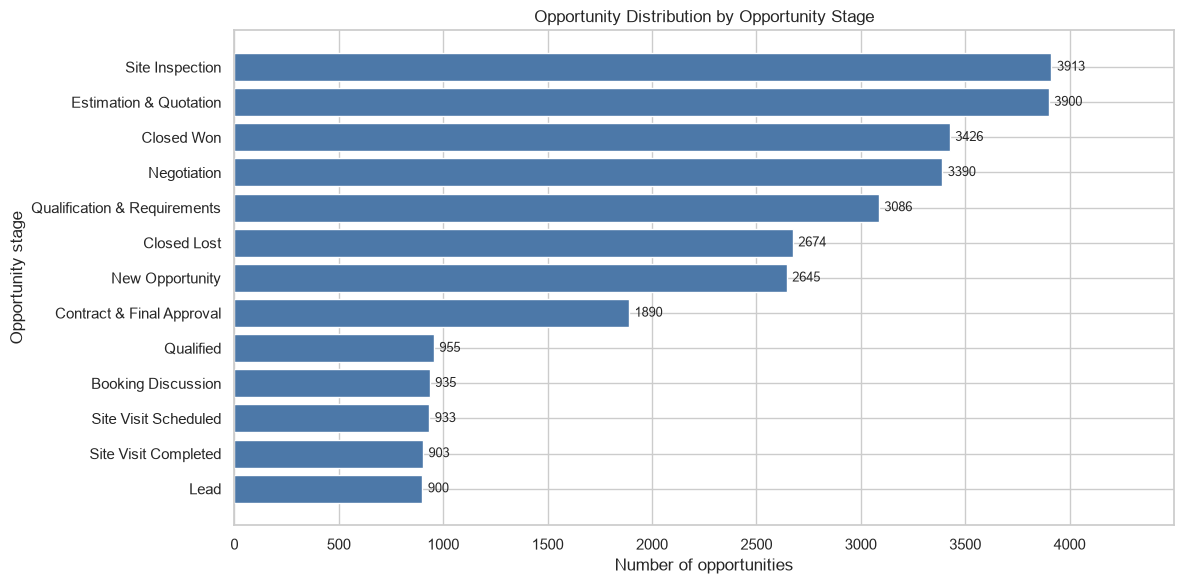

,Opportunity_Stage,Opportunity_Count
0,Site Inspection,3913
1,Estimation & Quotation,3900
2,Closed Won,3426
3,Negotiation,3390
4,Qualification & Requirements,3086
5,Closed Lost,2674
6,New Opportunity,2645
7,Contract & Final Approval,1890
8,Qualified,955
9,Booking Discussion,935


In [4]:
# 1B. Opportunity-stage representation (use Opportunity_Stage, not Outcome)
# This chart represents pipeline distribution by the current opportunity stage.
stage_counts = (
    raw["Opportunity_Stage"]
    .fillna("Unknown")
    .astype(str)
    .value_counts()
    .rename_axis("Opportunity_Stage")
    .reset_index(name="Opportunity_Count")
)

fig, ax = plt.subplots(figsize=(12, 6))
stage_counts = stage_counts.sort_values("Opportunity_Count", ascending=True)
bars = ax.barh(stage_counts["Opportunity_Stage"], stage_counts["Opportunity_Count"], color="#4c78a8")
ax.bar_label(bars, fmt="%.0f", padding=4, fontsize=9)
ax.set_title("Opportunity Distribution by Opportunity Stage")
ax.set_xlabel("Number of opportunities")
ax.set_ylabel("Opportunity stage")
ax.set_xlim(0, max(1, stage_counts["Opportunity_Count"].max() * 1.15))
plt.tight_layout()
plt.show()

display(stage_counts.sort_values("Opportunity_Count", ascending=False))

## 2. Monthly sales trend and forecast

Keep the forecast approach, but ensure the trend is built from actual close dates instead of assigning missing close dates to lead creation dates. Future close dates are reported and excluded from realized historical revenue until confirmed.

Won rows missing Actual_Close_Date: 0
Won rows with future Actual_Close_Date: 120


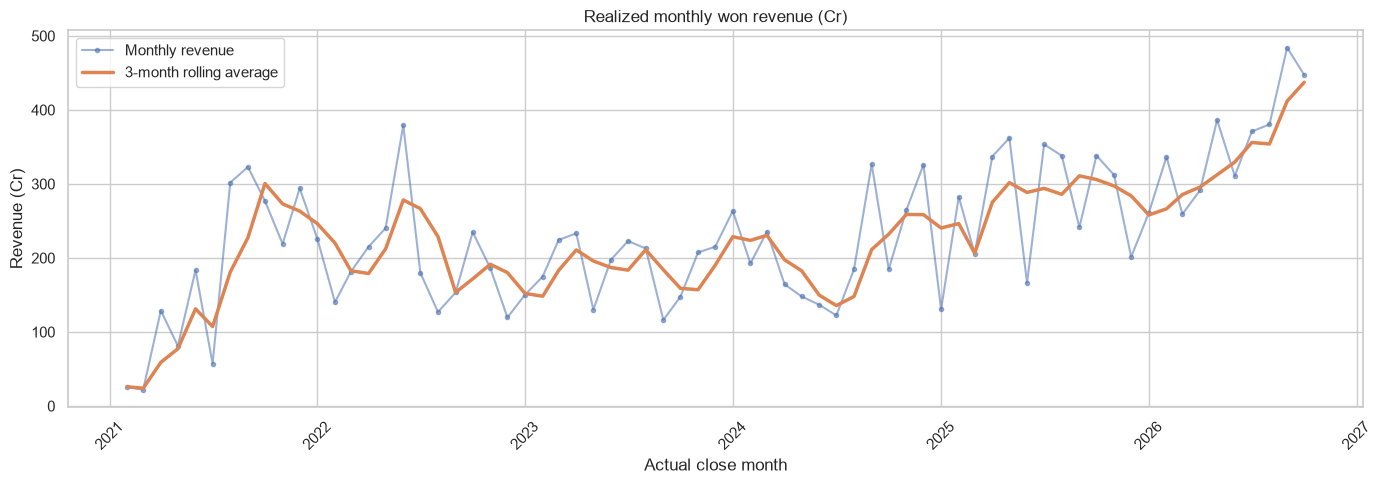

Chronological holdout MAE (Cr/month): 84.93
Forecast model: Random Forest lag/calendar model


,Forecast_Won_Revenue_Cr
2026-11-01,406.38
2026-12-01,412.12
2027-01-01,390.96
2027-02-01,395.04
2027-03-01,390.71
2027-04-01,393.85
2027-05-01,414.94
2027-06-01,404.15
2027-07-01,415.11
2027-08-01,415.50


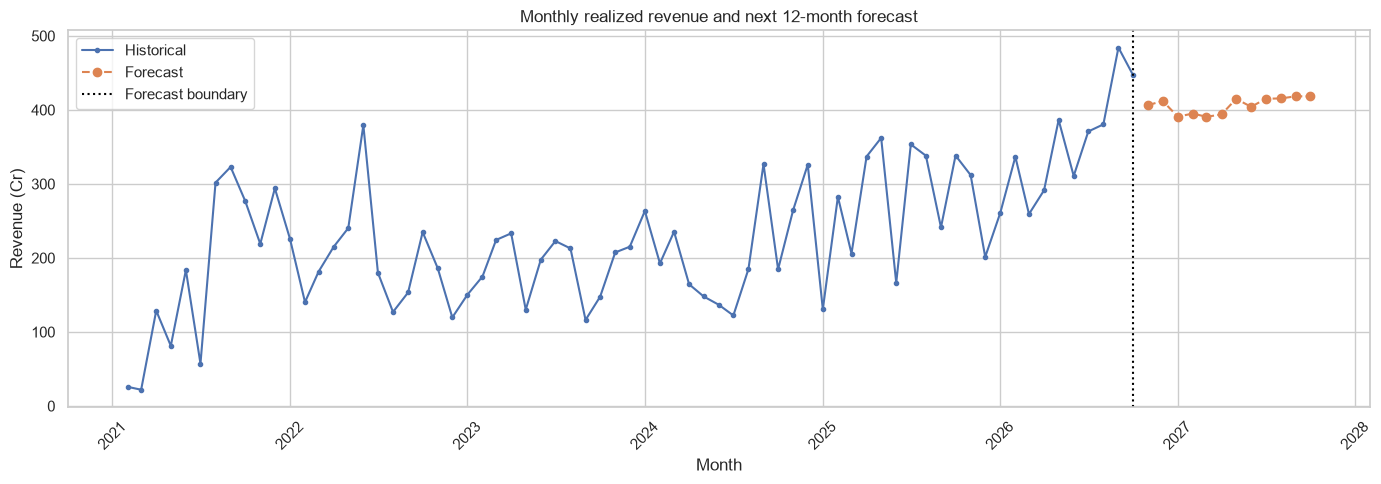

In [5]:
TODAY = pd.Timestamp.today().normalize()
won_rows = raw[raw["Is_Won"]].copy()
missing_close = won_rows["Actual_Close_Date"].isna()
future_close = won_rows["Actual_Close_Date"].notna() & (won_rows["Actual_Close_Date"] > TODAY)
print("Won rows missing Actual_Close_Date:", int(missing_close.sum()))
print("Won rows with future Actual_Close_Date:", int(future_close.sum()))

valid_won = won_rows[
    won_rows["Actual_Close_Date"].notna() &
    (won_rows["Actual_Close_Date"] <= TODAY) &
    won_rows["Final_Price_Cr"].notna()
].copy()
if valid_won.empty:
    raise ValueError("No won rows have a valid non-future Actual_Close_Date and Final_Price_Cr.")
valid_won["Revenue_Month"] = valid_won["Actual_Close_Date"].dt.to_period("M").dt.to_timestamp()
monthly_revenue = valid_won.groupby("Revenue_Month")["Final_Price_Cr"].sum().sort_index()
monthly_revenue = monthly_revenue.asfreq("MS", fill_value=0.0)
monthly_revenue.index.name = "Month"

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(monthly_revenue.index, monthly_revenue.values, marker="o", markersize=3, alpha=.55, label="Monthly revenue")
ax.plot(monthly_revenue.index, monthly_revenue.rolling(3, min_periods=1).mean(), linewidth=2.5, label="3-month rolling average")
ax.set(title="Realized monthly won revenue (Cr)", xlabel="Actual close month", ylabel="Revenue (Cr)")
ax.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

def make_features(series):
    d = pd.DataFrame({"y": series})
    for lag in [1, 2, 3, 6, 12]:
        d[f"lag_{lag}"] = d["y"].shift(lag)
    d["roll3"] = d["y"].shift(1).rolling(3).mean()
    d["roll12"] = d["y"].shift(1).rolling(12).mean()
    d["month"] = d.index.month
    d["year"] = d.index.year
    return d.dropna()

horizon = 12
last_month = monthly_revenue.index.max()
future_index = pd.date_range(last_month + pd.offsets.MonthBegin(1), periods=horizon, freq="MS")
feat = make_features(monthly_revenue)
forecast_values = []
model_used = "Seasonal-naive fallback"
if len(feat) >= 18:
    X, y = feat.drop(columns="y"), feat["y"]
    if len(feat) >= 30:
        split = len(feat) - min(12, max(3, len(feat)//5))
        val_model = RandomForestRegressor(n_estimators=300, min_samples_leaf=2, random_state=42)
        val_model.fit(X.iloc[:split], y.iloc[:split])
        print("Chronological holdout MAE (Cr/month):", round(mean_absolute_error(y.iloc[split:], val_model.predict(X.iloc[split:])), 2))
    model = RandomForestRegressor(n_estimators=400, min_samples_leaf=2, random_state=42)
    model.fit(X, y)
    history = monthly_revenue.copy()
    for dt in future_index:
        row = {f"lag_{lag}": float(history.iloc[-lag]) if len(history) >= lag else float(history.mean()) for lag in [1, 2, 3, 6, 12]}
        row["roll3"] = float(history.iloc[-3:].mean())
        row["roll12"] = float(history.iloc[-12:].mean())
        row["month"], row["year"] = dt.month, dt.year
        pred = max(0.0, float(model.predict(pd.DataFrame([row]))[0]))
        forecast_values.append(pred)
        history.loc[dt] = pred
    model_used = "Random Forest lag/calendar model"
else:
    for dt in future_index:
        prior = dt - pd.DateOffset(years=1)
        forecast_values.append(float(monthly_revenue.get(prior, monthly_revenue.mean())))
forecast = pd.Series(forecast_values, index=future_index, name="Forecast_Won_Revenue_Cr")
print("Forecast model:", model_used)
display(forecast.to_frame().round(2))

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(monthly_revenue.index, monthly_revenue.values, label="Historical", marker="o", markersize=3)
ax.plot(forecast.index, forecast.values, label="Forecast", linestyle="--", marker="o")
ax.axvline(last_month, color="black", linestyle=":", label="Forecast boundary")
ax.set(title="Monthly realized revenue and next 12-month forecast", xlabel="Month", ylabel="Revenue (Cr)")
ax.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


## 3. Sales representative performance — labels on every bar

Each win-rate bar has its percentage printed at the end. Revenue charts display revenue values, not win-rate values.

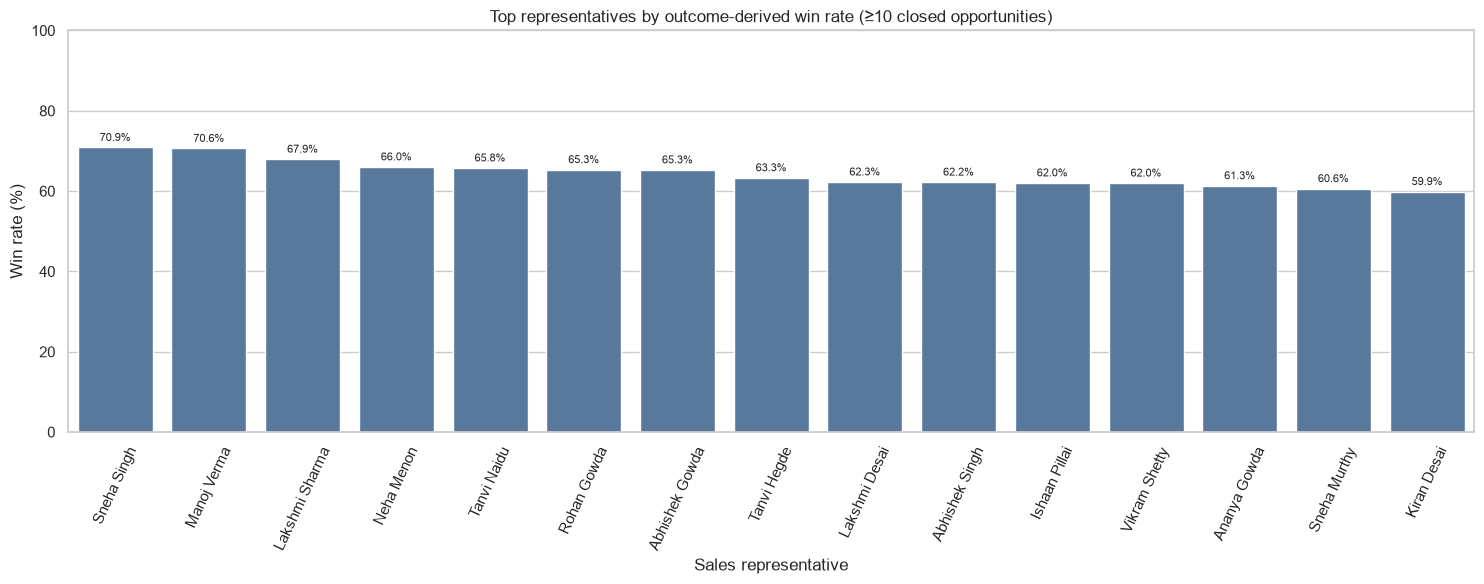

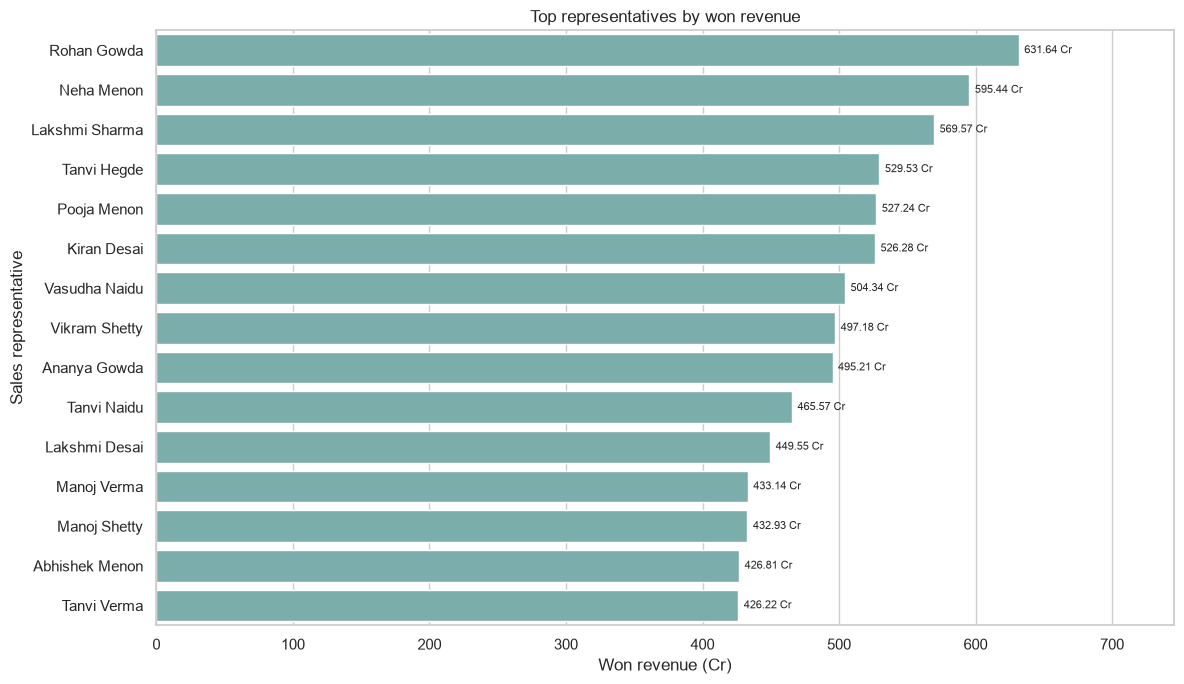

,Sales_Representative_Name,Wins,Losses,Closed_Opportunities,Won_Revenue_Cr,Win_Rate_Pct
33,Sneha Singh,90,37,127,376.38,70.87
13,Manoj Verma,89,37,126,433.14,70.63
11,Lakshmi Sharma,106,50,156,569.57,67.95
18,Neha Menon,103,53,156,595.44,66.03
35,Tanvi Naidu,96,50,146,465.57,65.75
26,Rohan Gowda,115,61,176,631.64,65.34
0,Abhishek Gowda,79,42,121,419.31,65.29
34,Tanvi Hegde,107,62,169,529.53,63.31
10,Lakshmi Desai,104,63,167,449.55,62.28
2,Abhishek Singh,89,54,143,419.54,62.24


In [6]:
# Build representative-level metrics before plotting (fixes rep_eligible not defined).
rep = raw.groupby("Sales_Representative_Name").agg(
    Wins=("Is_Won", "sum"),
    Losses=("Is_Lost", "sum"),
    Closed_Opportunities=("Is_Closed", "sum"),
    Won_Revenue_Cr=("Won_Revenue_Cr", "sum")
).reset_index()
rep["Win_Rate_Pct"] = np.where(
    rep["Closed_Opportunities"] > 0,
    100 * rep["Wins"] / rep["Closed_Opportunities"],
    np.nan
)
rep_eligible = rep[rep["Closed_Opportunities"] >= 10].copy()

top_rep_rate = rep_eligible.sort_values("Win_Rate_Pct", ascending=False).head(15)
fig, ax = plt.subplots(figsize=(15, 6))
sns.barplot(data=top_rep_rate, x="Sales_Representative_Name", y="Win_Rate_Pct", color="#4c78a8", ax=ax)
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3, fontsize=8, rotation=0)
ax.set(title="Top representatives by outcome-derived win rate (≥10 closed opportunities)",
       xlabel="Sales representative", ylabel="Win rate (%)")
ax.set_ylim(0, min(115, max(100, top_rep_rate["Win_Rate_Pct"].max()+15 if len(top_rep_rate) else 100)))
ax.tick_params(axis="x", rotation=65)
plt.tight_layout()
plt.show()

top_rep_revenue = rep.sort_values("Won_Revenue_Cr", ascending=False).head(15)
fig, ax = plt.subplots(figsize=(12, 7))
sns.barplot(data=top_rep_revenue, y="Sales_Representative_Name", x="Won_Revenue_Cr", color="#72b7b2", ax=ax)
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f Cr", padding=4, fontsize=8)
ax.set(title="Top representatives by won revenue", xlabel="Won revenue (Cr)", ylabel="Sales representative")
ax.set_xlim(0, max(1, top_rep_revenue["Won_Revenue_Cr"].max()*1.18 if len(top_rep_revenue) else 1))
plt.tight_layout()
plt.show()
display(rep.sort_values("Win_Rate_Pct", ascending=False).head(10).round(2))


## 4. Customer-type segmentation — percentage labels and revenue labels

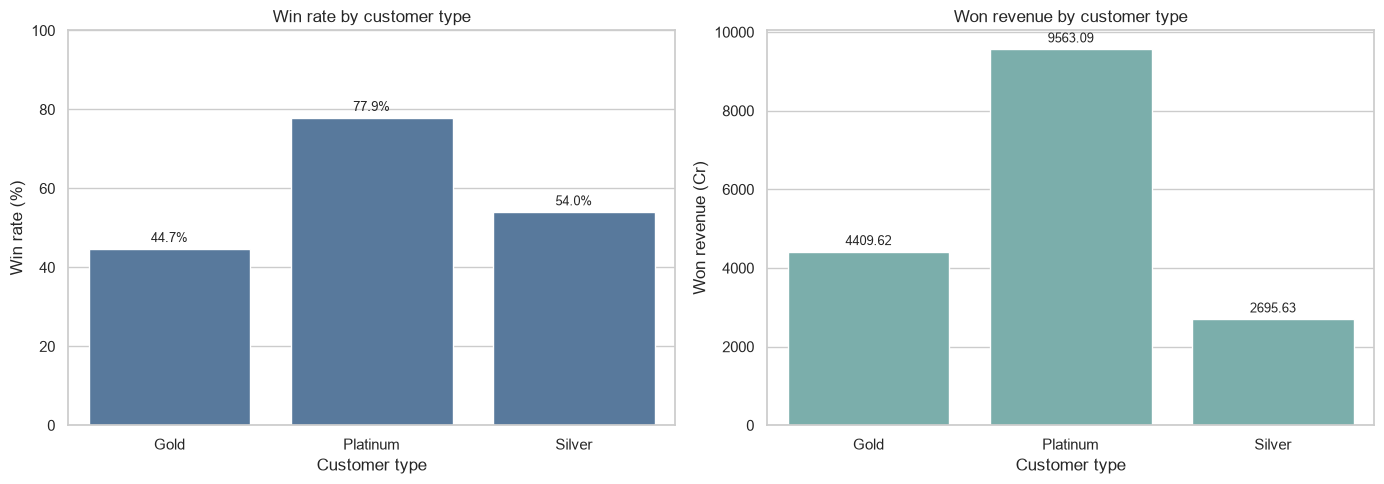

,Customer_Type,Opportunities,Wins,Losses,Won_Revenue_Cr,Closed,Win_Rate_Pct
1,Platinum,5481,1141,324,9563.09,1465,77.88
0,Gold,9444,1044,1292,4409.62,2336,44.69
2,Silver,14625,1241,1058,2695.63,2299,53.98


In [7]:
customer = raw.groupby("Customer_Type").agg(
    Opportunities=("Opportunity_ID", "nunique"), Wins=("Is_Won", "sum"),
    Losses=("Is_Lost", "sum"), Won_Revenue_Cr=("Won_Revenue_Cr", "sum")
).reset_index()
customer["Closed"] = customer["Wins"] + customer["Losses"]
customer["Win_Rate_Pct"] = np.where(customer["Closed"] > 0, 100*customer["Wins"]/customer["Closed"], np.nan)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(data=customer, x="Customer_Type", y="Win_Rate_Pct", color="#4c78a8", ax=axes[0])
for c in axes[0].containers: axes[0].bar_label(c, fmt="%.1f%%", padding=3, fontsize=9)
axes[0].set(title="Win rate by customer type", xlabel="Customer type", ylabel="Win rate (%)")
axes[0].set_ylim(0, min(110, max(100, customer["Win_Rate_Pct"].max()+12 if customer["Win_Rate_Pct"].notna().any() else 100)))
sns.barplot(data=customer, x="Customer_Type", y="Won_Revenue_Cr", color="#72b7b2", ax=axes[1])
for c in axes[1].containers: axes[1].bar_label(c, fmt="%.2f", padding=3, fontsize=9)
axes[1].set(title="Won revenue by customer type", xlabel="Customer type", ylabel="Won revenue (Cr)")
plt.tight_layout()
plt.show()
display(customer.sort_values("Won_Revenue_Cr", ascending=False).round(2))


## 5. Combination clustering

Combinations use six dimensions: `Customer_Type`, `Customer_Occupation`, `Contact_Type`, `Area`, `Opportunity_Stage`, and `Next_Action`. Clustering is based on outcome-derived measures and realized `Won_Revenue_Cr` rather than predictive `Opportunity_Value_Cr`. The opportunity value field is not used to drive the cluster assignment. KMeans is evaluated at **k = 5, 6, 7, 8**; the valid model with the highest silhouette score is retained.

In [8]:
dimensions = ["Customer_Type", "Customer_Occupation", "Contact_Type", "Area", "Opportunity_Stage", "Next_Action"]
raw["Is_Terminal_Stage"] = raw["Opportunity_Stage"].str.lower().isin(["closed won", "closed lost", "won", "lost"])

# Keep predictive values available in the source, but do not use them for combination ranking, treemap size, or clustering.
if "Opportunity_Value_Cr" not in raw.columns:
    raw["Opportunity_Value_Cr"] = 0.0
raw["Opportunity_Value_Cr"] = pd.to_numeric(raw["Opportunity_Value_Cr"], errors="coerce").fillna(0).clip(lower=0)

comb = raw.groupby(dimensions, dropna=False).agg(
    Opportunities=("Opportunity_ID", "nunique"),
    Wins=("Is_Won", "sum"),
    Losses=("Is_Lost", "sum"),
    Won_Revenue_Cr=("Won_Revenue_Cr", "sum")
).reset_index()

# Derive combination win rates from closed outcomes across the five non-stage dimensions.
# This avoids using the current stage itself to define the outcome rate.
rate_dimensions = ["Customer_Type", "Customer_Occupation", "Contact_Type", "Area", "Next_Action"]
rate_stats = raw.groupby(rate_dimensions, dropna=False).agg(
    Rate_Wins=("Is_Won", "sum"),
    Rate_Losses=("Is_Lost", "sum")
).reset_index()
rate_stats["Rate_Closed"] = rate_stats["Rate_Wins"] + rate_stats["Rate_Losses"]
rate_stats["Win_Rate_Pct"] = np.where(
    rate_stats["Rate_Closed"] > 0,
    100 * rate_stats["Rate_Wins"] / rate_stats["Rate_Closed"],
    np.nan
)
comb = comb.merge(
    rate_stats[rate_dimensions + ["Rate_Wins", "Rate_Losses", "Rate_Closed", "Win_Rate_Pct"]],
    on=rate_dimensions, how="left"
)
comb["Win_Rate_Fill"] = comb["Win_Rate_Pct"].fillna(0)
comb["Combination_Label"] = comb[dimensions].astype(str).agg(" | ".join, axis=1)

def rate_band(rate):
    if pd.isna(rate):
        return "No closed outcomes"
    if rate >= 80:
        return "High (≥80%)"
    if rate <= 20:
        return "Low (≤20%)"
    return "Medium (>20–<80%)"

colors = {
    "High (≥80%)": "#16803c",
    "Medium (>20–<80%)": "#f0ad00",
    "Low (≤20%)": "#d7191c",
    "No closed outcomes": "#d9d9d9"
}
comb["Win_Rate_Band"] = comb["Win_Rate_Pct"].apply(rate_band)

# Cluster only on realized outcome/revenue metrics. Predictive Opportunity_Value_Cr is intentionally excluded.
cluster_features = comb[["Opportunities", "Rate_Closed", "Win_Rate_Fill", "Won_Revenue_Cr"]].replace([np.inf, -np.inf], np.nan).fillna(0)
if len(comb) >= 3:
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(cluster_features)
    candidate_ks = [k for k in range(5, 9) if len(comb) > k]
    silhouette_results = []
    best_k, best_score = None, -1
    if len(comb) >= 6 and candidate_ks:
        for k in candidate_ks:
            labels = KMeans(n_clusters=k, random_state=42, n_init=20).fit_predict(X_scaled)
            if 1 < len(set(labels)) < len(labels):
                score = silhouette_score(X_scaled, labels, sample_size=min(3000, len(labels)), random_state=42)
                silhouette_results.append({"K": k, "Silhouette_Score": score})
                if score > best_score:
                    best_k, best_score = k, score
    if best_k is None:
        best_k = min(5, max(2, len(comb) - 1))
        print("Not enough valid candidates for k=5–8; using fallback k =", best_k)
    else:
        print("Silhouette scores for k=5–8:")
        display(pd.DataFrame(silhouette_results).sort_values("K").round(4))
        print(f"Selected KMeans k={best_k} with highest silhouette score={best_score:.4f}")
    km = KMeans(n_clusters=best_k, random_state=42, n_init=20)
    comb["KMeans_Cluster"] = km.fit_predict(X_scaled)
else:
    comb["KMeans_Cluster"] = 0
    print("Too few combinations for KMeans; assigned a single cluster.")

print("Unique combinations:", len(comb), "| clusters:", comb["KMeans_Cluster"].nunique())
display(comb.sort_values("Opportunities", ascending=False)[dimensions + [
    "Opportunities", "Rate_Closed", "Rate_Wins", "Win_Rate_Pct", "Won_Revenue_Cr", "Win_Rate_Band", "KMeans_Cluster"
]].head(15).round(2))

Silhouette scores for k=5–8:


,K,Silhouette_Score
0,5,0.6657
1,6,0.6676
2,7,0.6751
3,8,0.6763


Selected KMeans k=8 with highest silhouette score=0.6763
Unique combinations: 19528 | clusters: 8


,Customer_Type,Customer_Occupation,Contact_Type,Area,Opportunity_Stage,Next_Action,Opportunities,Rate_Closed,Rate_Wins,Win_Rate_Pct,Won_Revenue_Cr,Win_Rate_Band,KMeans_Cluster
15650,Silver,IT Professional,Referral,Electronic City,Closed Won,No further action - closed won,22,22,22,100.0,38.96,High (≥80%),5
15206,Silver,IT Professional,Facebook,Hebbal,Closed Lost,Record loss reason and close follow-up,17,17,0,0.0,0.00,Low (≤20%),3
15068,Silver,IT Professional,Email,Electronic City,Closed Lost,Mark as lost - record reason,16,16,0,0.0,0.00,Low (≤20%),3
15564,Silver,IT Professional,Property Portal,Hebbal,Closed Lost,Record loss reason and close follow-up,16,16,0,0.0,0.00,Low (≤20%),3
15845,Silver,IT Professional,Website,Electronic City,Closed Won,No further action - closed won,16,16,16,100.0,31.64,High (≥80%),5
15844,Silver,IT Professional,Website,Electronic City,Closed Lost,Mark as lost - record reason,15,15,0,0.0,0.00,Low (≤20%),3
15374,Silver,IT Professional,Online Portal,Electronic City,Closed Won,No further action - closed won,15,15,15,100.0,22.34,High (≥80%),3
15707,Silver,IT Professional,Walk-in,Electronic City,Closed Won,No further action - closed won,15,15,15,100.0,42.83,High (≥80%),5
15069,Silver,IT Professional,Email,Electronic City,Closed Won,No further action - closed won,14,14,14,100.0,27.36,High (≥80%),5
15891,Silver,IT Professional,Website,Hebbal,Closed Lost,Record loss reason and close follow-up,14,14,0,0.0,0.00,Low (≤20%),3


## 6. Static treemap — opportunity count size, win-rate color

Tile area represents the **number of opportunities** in each combination. Tile color represents outcome-derived win rate: green ≥80%, red ≤20%, and amber >20% to <80%; combinations without closed outcomes are grey. The treemap shows up to 60 combinations and includes all available green, amber, and red groups. Labels explicitly show customer category/type (for example, Gold or Platinum where present), contact type, customer occupation, and opportunity stage.

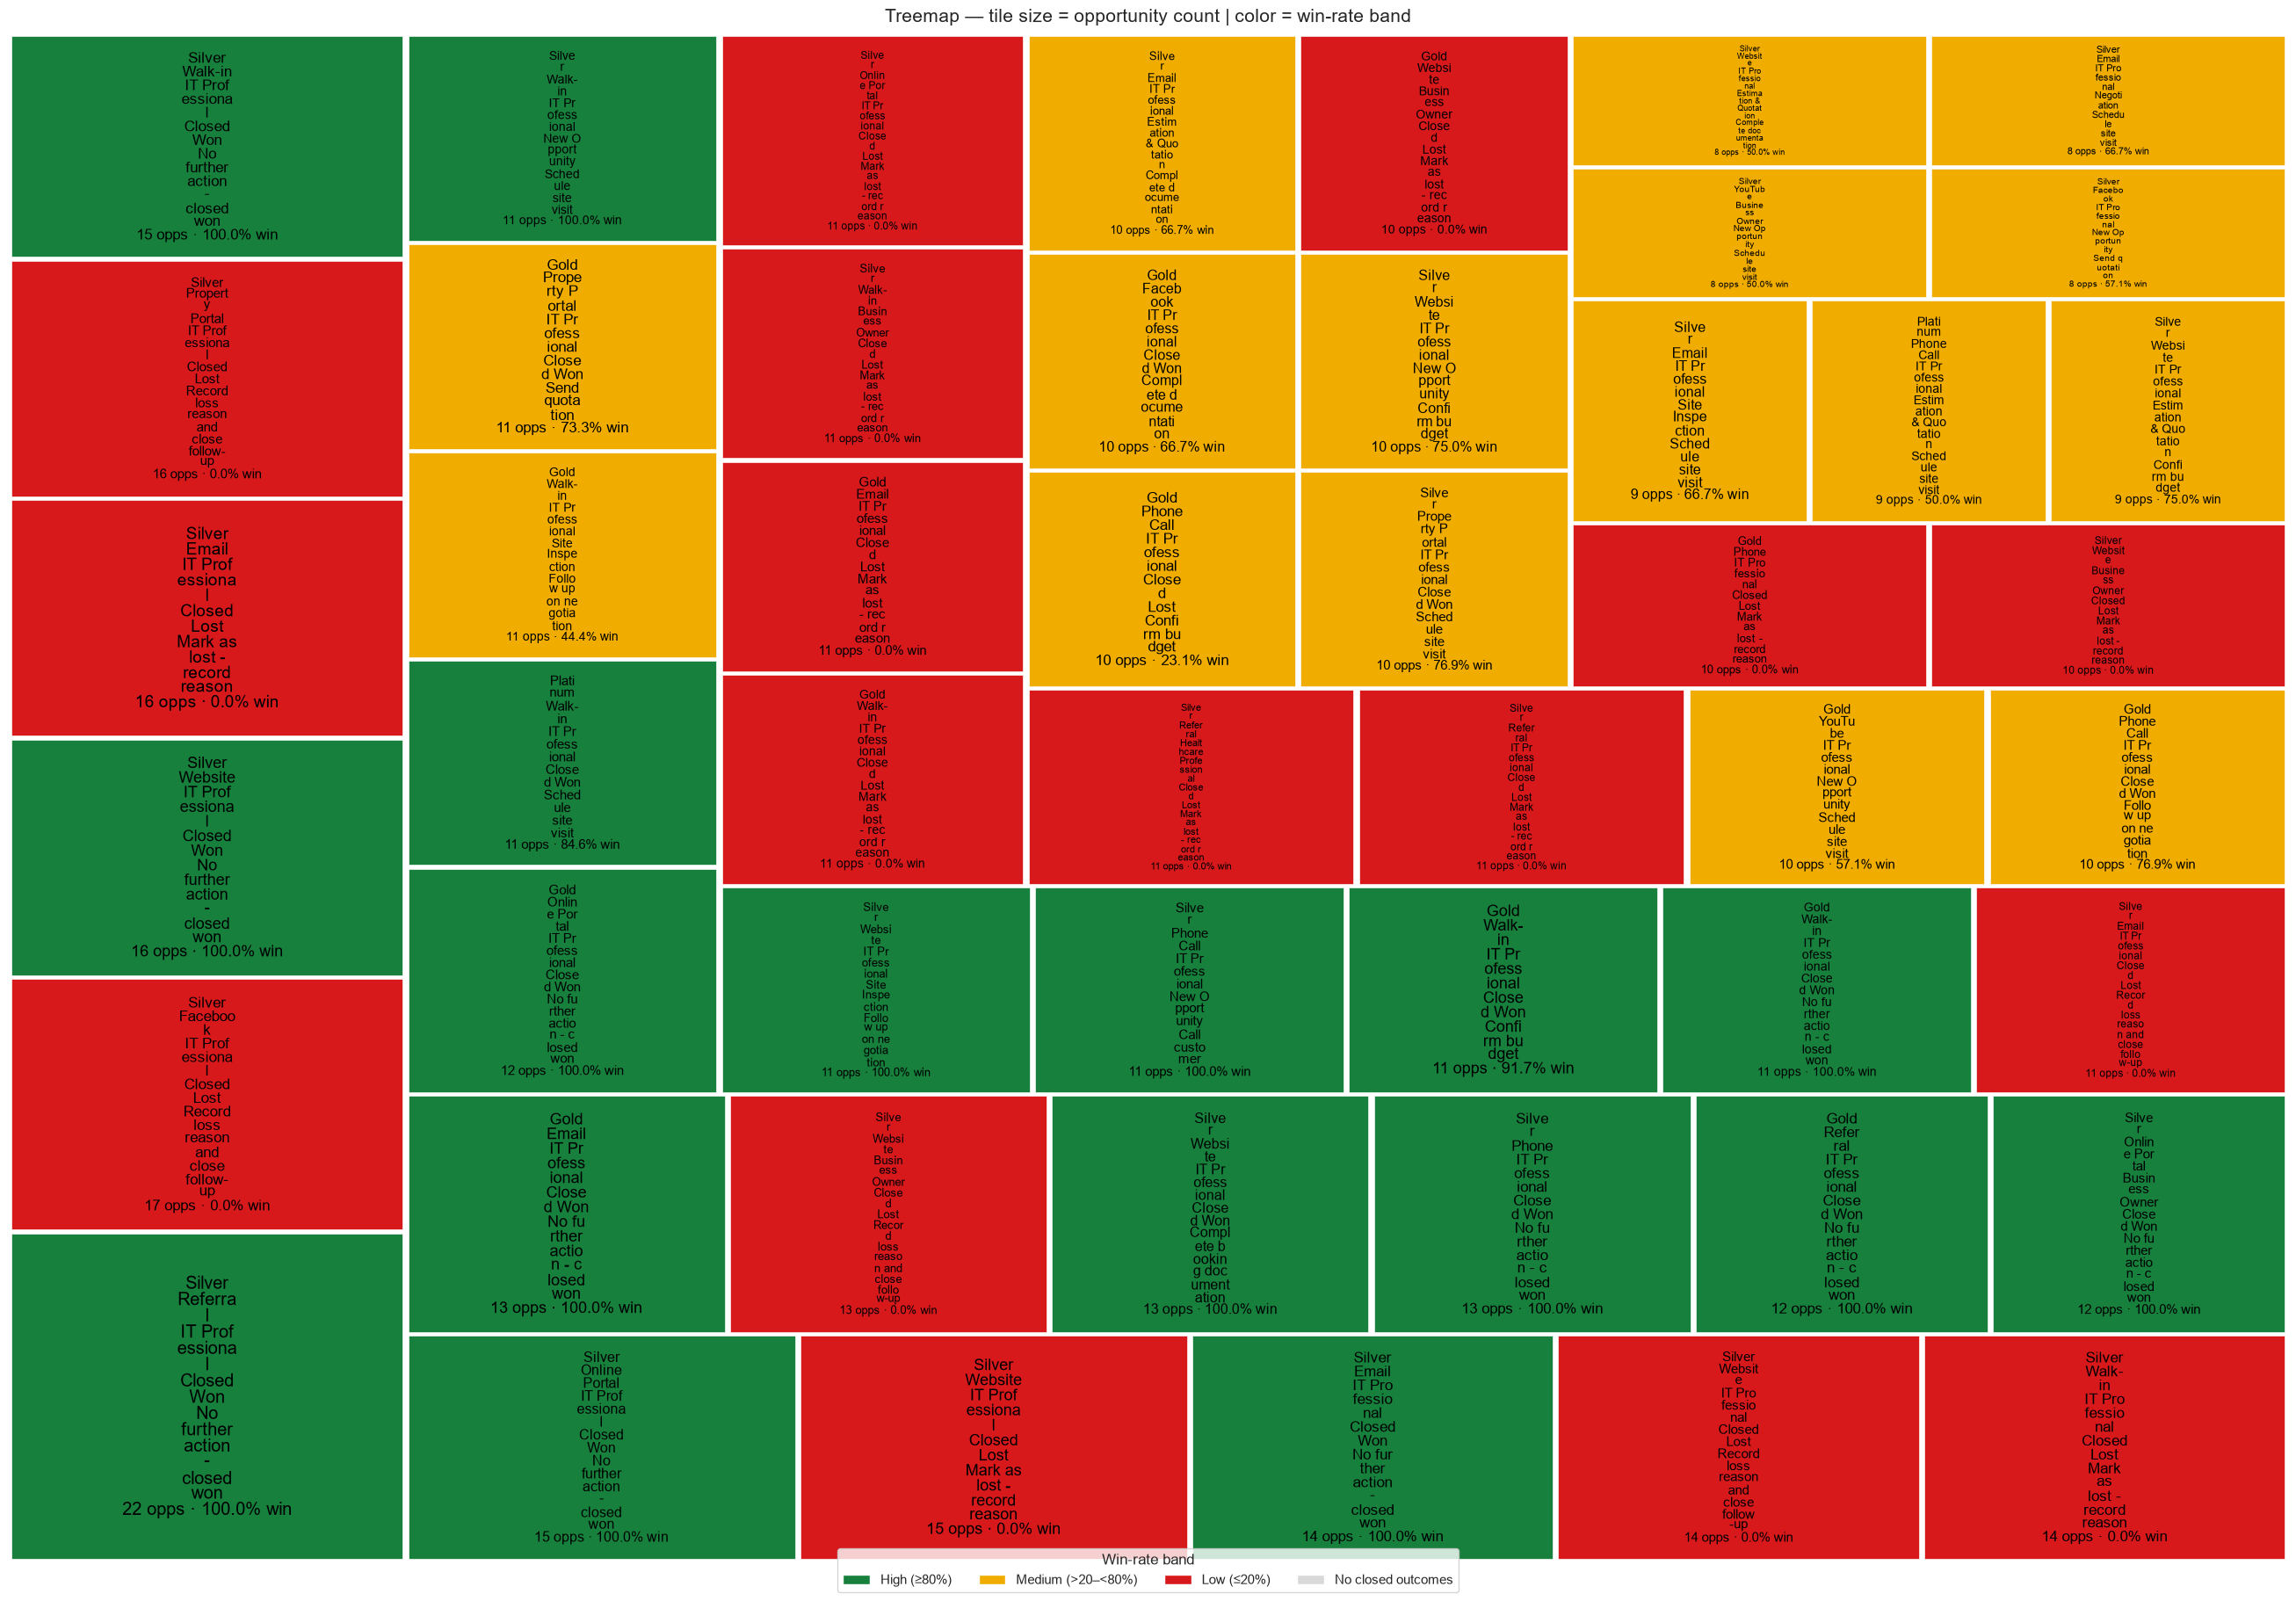

,Customer_Type,Customer_Occupation,Contact_Type,Area,Opportunity_Stage,Next_Action,Opportunities,Win_Rate_Pct,Win_Rate_Band
0,Silver,IT Professional,Referral,Electronic City,Closed Won,No further action - closed won,22,100.00,High (≥80%)
34,Silver,IT Professional,Facebook,Hebbal,Closed Lost,Record loss reason and close follow-up,17,0.00,Low (≤20%)
1,Silver,IT Professional,Website,Electronic City,Closed Won,No further action - closed won,16,100.00,High (≥80%)
35,Silver,IT Professional,Email,Electronic City,Closed Lost,Mark as lost - record reason,16,0.00,Low (≤20%)
36,Silver,IT Professional,Property Portal,Hebbal,Closed Lost,Record loss reason and close follow-up,16,0.00,Low (≤20%)
3,Silver,IT Professional,Walk-in,Electronic City,Closed Won,No further action - closed won,15,100.00,High (≥80%)
2,Silver,IT Professional,Online Portal,Electronic City,Closed Won,No further action - closed won,15,100.00,High (≥80%)
37,Silver,IT Professional,Website,Electronic City,Closed Lost,Mark as lost - record reason,15,0.00,Low (≤20%)
4,Silver,IT Professional,Email,Electronic City,Closed Won,No further action - closed won,14,100.00,High (≥80%)
39,Silver,IT Professional,Website,Hebbal,Closed Lost,Record loss reason and close follow-up,14,0.00,Low (≤20%)


In [9]:
# Select up to 50 combinations by opportunity count, ensuring each available win-rate band is represented.
eligible = comb[comb["Opportunities"] > 0].copy()
if eligible.empty:
    raise ValueError("No combinations with opportunities were found.")

band_order = ["High (≥80%)", "Medium (>20–<80%)", "Low (≤20%)"]
selected_parts = []
# Reserve space for each win-rate color band, then fill remaining slots by opportunity count.
slots_per_band = 17
for band in band_order:
    band_rows = eligible[eligible["Win_Rate_Band"] == band].sort_values("Opportunities", ascending=False)
    selected_parts.append(band_rows.head(slots_per_band))

treemap_data = pd.concat(selected_parts, ignore_index=True).drop_duplicates(subset=dimensions)
if len(treemap_data) < 50:
    remaining = eligible[~eligible["Combination_Label"].isin(treemap_data["Combination_Label"])].sort_values("Opportunities", ascending=False)
    treemap_data = pd.concat([treemap_data, remaining.head(50 - len(treemap_data))], ignore_index=True)
treemap_data = treemap_data.sort_values("Opportunities", ascending=False).head(50).copy()

# Tile text shows values only (no column names): all five combination dimensions plus opportunity count and win rate.
def safe_label(value):
    value = str(value).strip()
    if value.lower() in {"nan", "none", ""}:
        return "Unknown"
    return value

try:
    import squarify
    import textwrap
    from matplotlib.patches import Rectangle
except ImportError as exc:
    raise ImportError("Install squarify with `%pip install squarify`, then rerun this cell.") from exc

# Generate the treemap rectangles directly so each label can be clipped to its own tile.
sizes = treemap_data["Opportunities"].clip(lower=1).astype(float).tolist()
normalized_sizes = squarify.normalize_sizes(sizes, 100, 100)
rects = squarify.squarify(normalized_sizes, x=0, y=0, dx=100, dy=100)

fig, ax = plt.subplots(figsize=(26, 18))
ax.set_xlim(0, 100)
ax.set_ylim(0, 100)
ax.set_aspect("auto")
ax.axis("off")

for idx, (rect, (_, row)) in enumerate(zip(rects, treemap_data.iterrows())):
    # Tiny inset and thin white edge keep tiles visually separated without large gaps.
    inset = 0.12
    x = rect["x"] + inset
    y = rect["y"] + inset
    w = max(0.05, rect["dx"] - 2 * inset)
    h = max(0.05, rect["dy"] - 2 * inset)

    tile = Rectangle(
        (x, y), w, h,
        facecolor=colors.get(row["Win_Rate_Band"], "#d9d9d9"),
        edgecolor="white", linewidth=0.45, antialiased=True
    )
    ax.add_patch(tile)

    # Keep each value on its own row; wrap long values based on tile width.
    chars_per_line = max(5, min(22, int(w * 0.42)))
    values = [
        safe_label(row["Customer_Type"]),
        safe_label(row["Contact_Type"]),
        safe_label(row["Customer_Occupation"]),
        safe_label(row["Opportunity_Stage"]),
        safe_label(row["Next_Action"])
    ]
    wrapped_values = []
    for value in values:
        wrapped_values.extend(textwrap.wrap(value, width=chars_per_line, break_long_words=True, break_on_hyphens=True) or [" "])
    rate_text = "N/A" if pd.isna(row["Win_Rate_Pct"]) else f"{row['Win_Rate_Pct']:.1f}%"
    wrapped_values.append(f"{int(row['Opportunities'])} opps · {rate_text} win")

    label_text = "\n".join(wrapped_values)

    # Increase label size while calculating a safe fit for each tile's width and height.
    # The figure uses a 100 x 100 data area; convert each tile's dimensions to approximate points.
    line_count = max(1, len(wrapped_values))
    longest_line = max((len(line) for line in wrapped_values), default=1)
    points_per_x_unit = (fig.get_figwidth() * 72) / 100
    points_per_y_unit = (fig.get_figheight() * 72) / 100
    width_fit = (w * points_per_x_unit) / max(1, longest_line * 0.58)
    height_fit = (h * points_per_y_unit) / (line_count * 1.12)
    min_side = min(w, h)
    preferred_fontsize = 7.0 + min_side * 0.42
    fontsize = max(5.0, min(16.0, preferred_fontsize, width_fit, height_fit))
    text_obj = ax.text(
        x + w / 2, y + h / 2, label_text,
        ha="center", va="center",
        fontsize=fontsize, color="black",
        linespacing=1.0, wrap=True,
        clip_on=True, zorder=2
    )
    text_obj.set_clip_path(tile)

ax.set_title("Treemap — tile size = opportunity count | color = win-rate band", fontsize=15, pad=10)
legend = [Patch(facecolor=colors[k], edgecolor="white", label=k) for k in ["High (≥80%)", "Medium (>20–<80%)", "Low (≤20%)", "No closed outcomes"]]
ax.legend(handles=legend, title="Win-rate band", loc="lower center", bbox_to_anchor=(0.5, -0.025), ncol=4, frameon=True)
plt.tight_layout(pad=0.2)
plt.show()

display(treemap_data[dimensions + ["Opportunities", "Win_Rate_Pct", "Win_Rate_Band"]].round(2))

## 7. Column charts — top/bottom combinations by realized won revenue

The top and bottom 10 combinations are ranked by `Won_Revenue_Cr` (realized revenue), not predictive opportunity value. Bars are labelled with revenue in Cr; a separate chart shows win rate using the same green/amber/red bands.

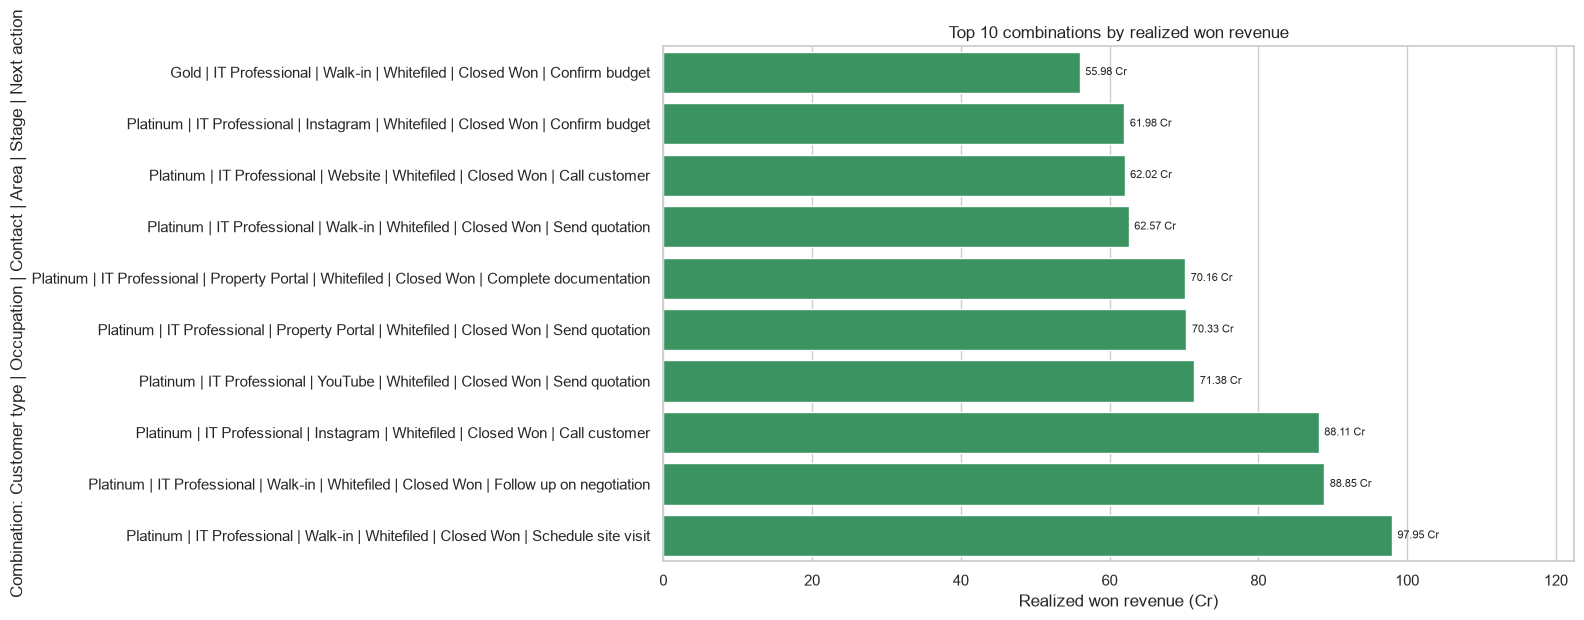

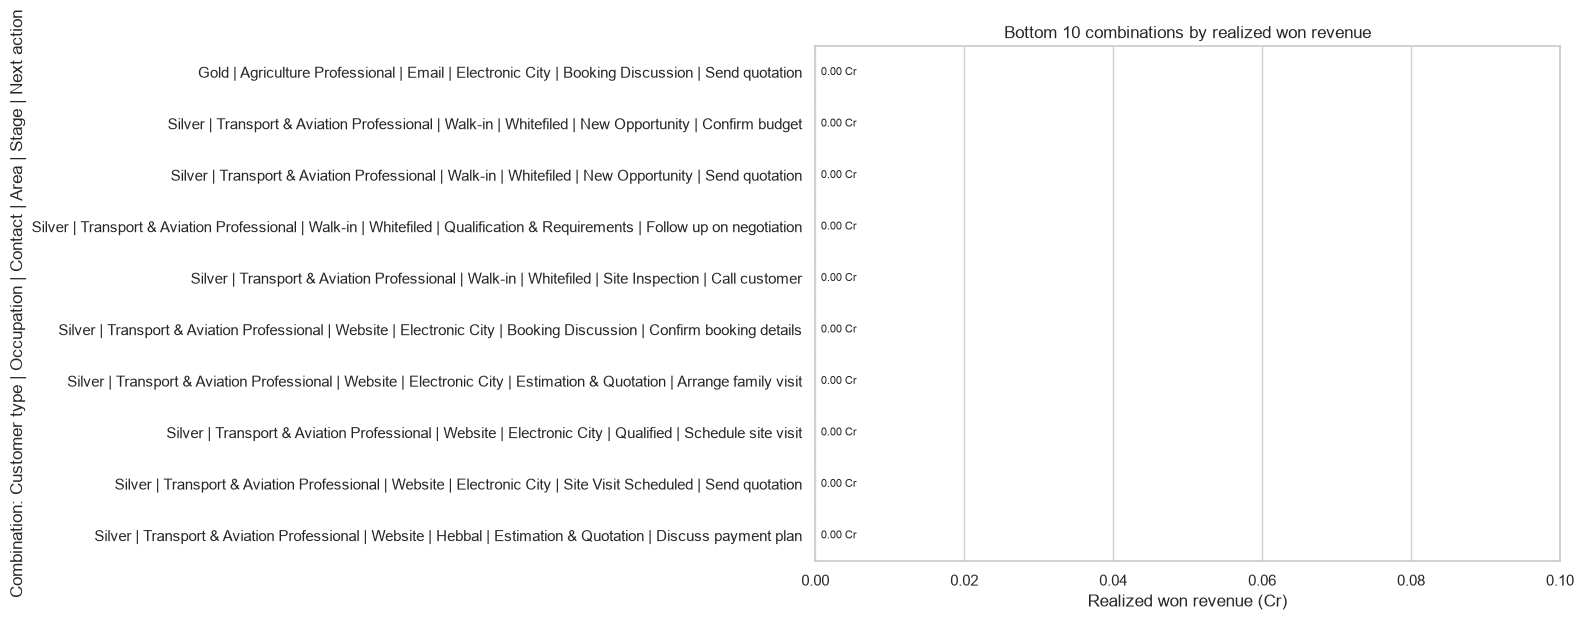

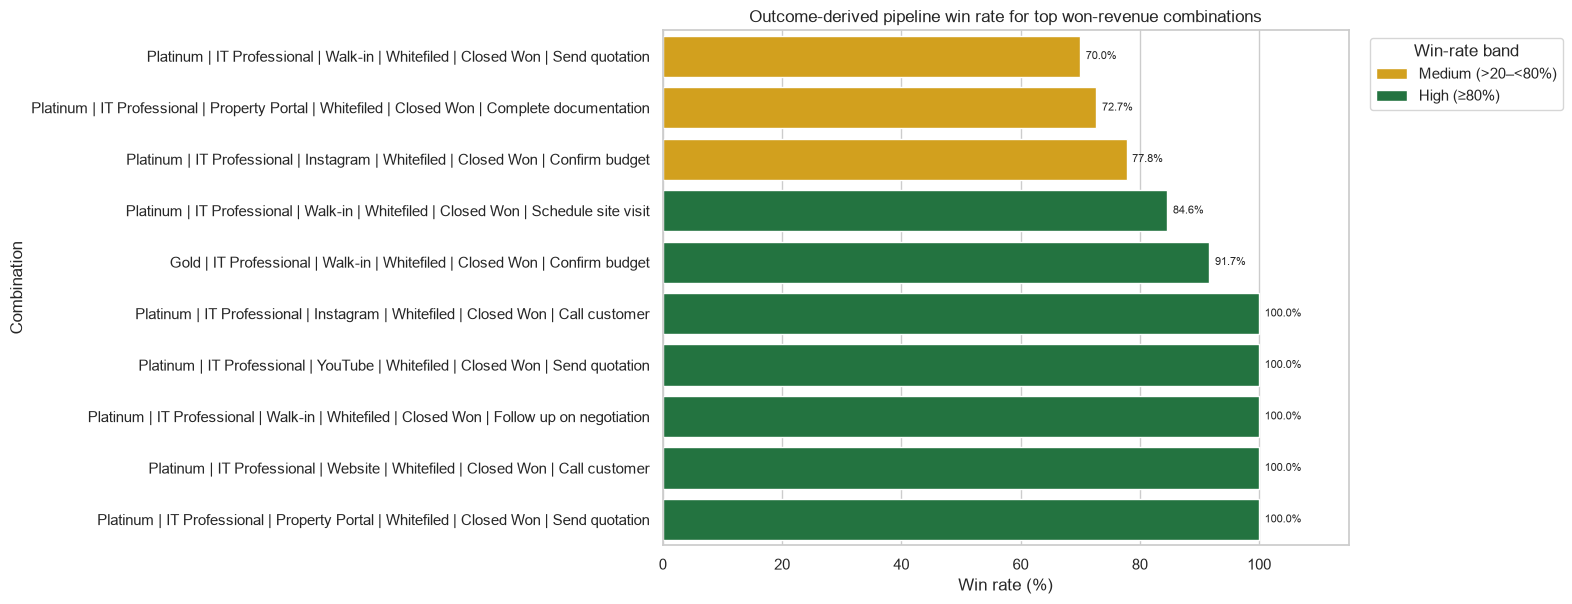

Top combinations by realized won revenue:


,Customer_Type,Customer_Occupation,Contact_Type,Area,Opportunity_Stage,Next_Action,Opportunities,Rate_Closed,Win_Rate_Pct,Won_Revenue_Cr,Win_Rate_Band,KMeans_Cluster
8957,Platinum,IT Professional,Walk-in,Whitefiled,Closed Won,Schedule site visit,11,13,84.62,97.95,High (≥80%),5
8956,Platinum,IT Professional,Walk-in,Whitefiled,Closed Won,Follow up on negotiation,10,10,100.00,88.85,High (≥80%),5
8662,Platinum,IT Professional,Instagram,Whitefiled,Closed Won,Call customer,10,10,100.00,88.11,High (≥80%),5
9092,Platinum,IT Professional,YouTube,Whitefiled,Closed Won,Send quotation,8,8,100.00,71.38,High (≥80%),5
8827,Platinum,IT Professional,Property Portal,Whitefiled,Closed Won,Send quotation,8,8,100.00,70.32,High (≥80%),5
8823,Platinum,IT Professional,Property Portal,Whitefiled,Closed Won,Complete documentation,8,11,72.73,70.16,Medium (>20–<80%),5
8958,Platinum,IT Professional,Walk-in,Whitefiled,Closed Won,Send quotation,7,10,70.00,62.57,Medium (>20–<80%),5
9034,Platinum,IT Professional,Website,Whitefiled,Closed Won,Call customer,7,7,100.00,62.02,High (≥80%),5
8664,Platinum,IT Professional,Instagram,Whitefiled,Closed Won,Confirm budget,7,9,77.78,61.98,Medium (>20–<80%),5
3838,Gold,IT Professional,Walk-in,Whitefiled,Closed Won,Confirm budget,11,12,91.67,55.98,High (≥80%),5


Bottom combinations by realized won revenue:


,Customer_Type,Customer_Occupation,Contact_Type,Area,Opportunity_Stage,Next_Action,Opportunities,Rate_Closed,Win_Rate_Pct,Won_Revenue_Cr,Win_Rate_Band,KMeans_Cluster
0,Gold,Agriculture Professional,Email,Electronic City,Booking Discussion,Send quotation,1,0,NaN,0.0,No closed outcomes,1
19505,Silver,Transport & Aviation Professional,Walk-in,Whitefiled,New Opportunity,Confirm budget,2,0,NaN,0.0,No closed outcomes,4
19506,Silver,Transport & Aviation Professional,Walk-in,Whitefiled,New Opportunity,Send quotation,1,0,NaN,0.0,No closed outcomes,1
19507,Silver,Transport & Aviation Professional,Walk-in,Whitefiled,Qualification & Requirements,Follow up on negotiation,1,0,NaN,0.0,No closed outcomes,1
19508,Silver,Transport & Aviation Professional,Walk-in,Whitefiled,Site Inspection,Call customer,1,0,NaN,0.0,No closed outcomes,1
19509,Silver,Transport & Aviation Professional,Website,Electronic City,Booking Discussion,Confirm booking details,1,0,NaN,0.0,No closed outcomes,1
19510,Silver,Transport & Aviation Professional,Website,Electronic City,Estimation & Quotation,Arrange family visit,1,0,NaN,0.0,No closed outcomes,1
19511,Silver,Transport & Aviation Professional,Website,Electronic City,Qualified,Schedule site visit,1,0,NaN,0.0,No closed outcomes,1
19512,Silver,Transport & Aviation Professional,Website,Electronic City,Site Visit Scheduled,Send quotation,1,0,NaN,0.0,No closed outcomes,1
19513,Silver,Transport & Aviation Professional,Website,Hebbal,Estimation & Quotation,Discuss payment plan,1,0,NaN,0.0,No closed outcomes,1


In [10]:
# Rank combinations by realized won revenue.
ranked = comb[comb["Opportunities"] > 0].copy()
top_revenue = ranked.sort_values("Won_Revenue_Cr", ascending=False).head(10).copy()
bottom_revenue = ranked.sort_values("Won_Revenue_Cr", ascending=True).head(10).copy()

def plot_combo_value(data, title, color):
    if data.empty:
        print("No combinations available:", title)
        return
    data = data.sort_values("Won_Revenue_Cr", ascending=True)
    fig, ax = plt.subplots(figsize=(16, max(5, 0.62 * len(data))))
    sns.barplot(data=data, y="Combination_Label", x="Won_Revenue_Cr", color=color, ax=ax)
    for container in ax.containers:
        ax.bar_label(container, fmt="%.2f Cr", padding=4, fontsize=8)
    ax.set_title(title)
    ax.set_xlabel("Realized won revenue (Cr)")
    ax.set_ylabel("Combination: Customer type | Occupation | Contact | Area | Stage | Next action")
    ax.set_xlim(0, max(0.1, data["Won_Revenue_Cr"].max() * 1.25))
    plt.tight_layout()
    plt.show()

plot_combo_value(top_revenue, "Top 10 combinations by realized won revenue", "#2ca25f")
plot_combo_value(bottom_revenue, "Bottom 10 combinations by realized won revenue", "#d7191c")

rate_view = top_revenue.dropna(subset=["Win_Rate_Pct"]).sort_values("Win_Rate_Pct", ascending=True)
if not rate_view.empty:
    fig, ax = plt.subplots(figsize=(16, max(5, 0.62 * len(rate_view))))
    sns.barplot(data=rate_view, y="Combination_Label", x="Win_Rate_Pct", hue="Win_Rate_Band",
                palette=colors, dodge=False, ax=ax)
    for container in ax.containers:
        ax.bar_label(container, fmt="%.1f%%", padding=4, fontsize=8)
    ax.set_title("Outcome-derived pipeline win rate for top won-revenue combinations")
    ax.set_xlabel("Win rate (%)")
    ax.set_ylabel("Combination")
    ax.set_xlim(0, min(120, max(100, rate_view["Win_Rate_Pct"].max() + 15)))
    ax.legend(title="Win-rate band", bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    plt.show()

print("Top combinations by realized won revenue:")
display(top_revenue[dimensions + ["Opportunities", "Rate_Closed", "Win_Rate_Pct",
                                  "Won_Revenue_Cr", "Win_Rate_Band", "KMeans_Cluster"]].round(2))
print("Bottom combinations by realized won revenue:")
display(bottom_revenue[dimensions + ["Opportunities", "Rate_Closed", "Win_Rate_Pct",
                                     "Won_Revenue_Cr", "Win_Rate_Band", "KMeans_Cluster"]].round(2))

## 8. Cluster-level results and clear pain points

KMeans cluster IDs are arbitrary. The table and charts sort clusters by won revenue and label revenue and win rate explicitly. Pain points are generated from the observed data: low win rate with meaningful closed volume, low revenue despite substantial opportunity volume, and missing/invalid close dates for wins.

,KMeans_Cluster,Combinations,Opportunities,Rate_Closed,Rate_Wins,Won_Revenue_Cr,Win_Rate_Pct,Win_Rate_Band
2,2,747,1427,1719,1427,9505.72,83.01,High (≥80%)
5,5,73,462,544,462,3221.54,84.93,High (≥80%)
0,0,2268,3253,3177,3177,2413.38,100.00,High (≥80%)
7,7,1569,2151,5073,2630,748.81,51.84,Medium (>20–<80%)
3,3,215,1681,1370,645,436.04,47.08,Medium (>20–<80%)
6,6,681,2125,4633,2669,342.84,57.61,Medium (>20–<80%)
1,1,10794,10794,1268,0,0.00,0.00,Low (≤20%)
4,4,3181,7657,971,20,0.00,2.06,Low (≤20%)


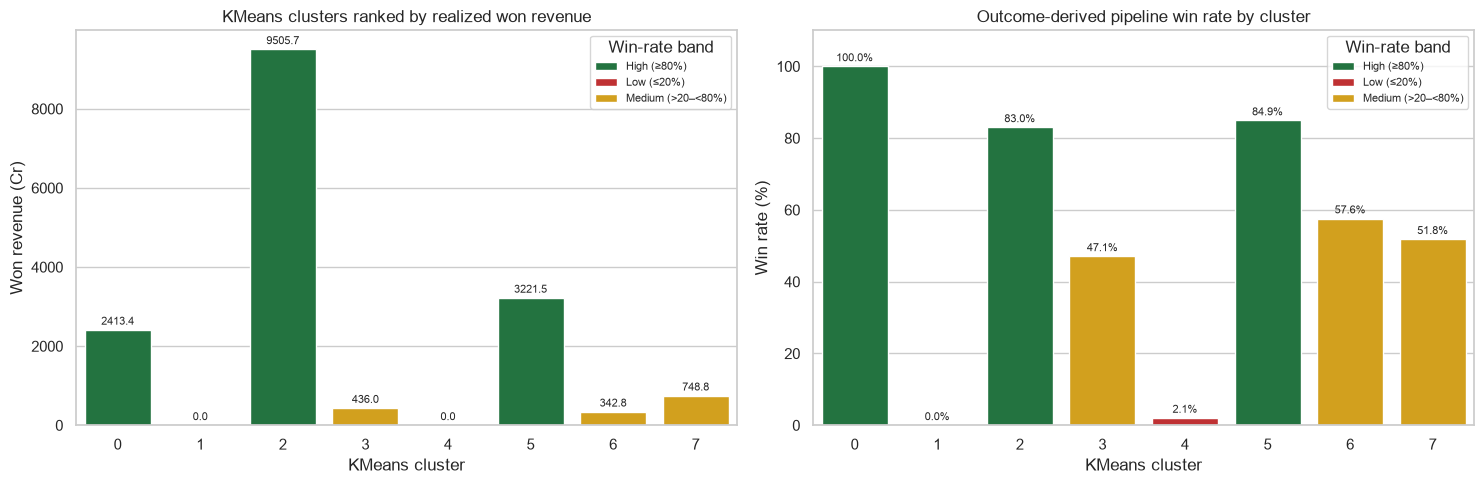

Pain point A — combinations with at least 5 closed outcomes and win rate ≤40%:


,Customer_Type,Customer_Occupation,Contact_Type,Area,Opportunity_Stage,Next_Action,Opportunities,Rate_Closed,Win_Rate_Pct,Won_Revenue_Cr,Win_Rate_Band
3663,Gold,IT Professional,Property Portal,Whitefiled,Closed Won,Follow up on negotiation,4,10,40.00,20.80,Medium (>20–<80%)
8771,Platinum,IT Professional,Phone Call,Whitefiled,Closed Won,Follow up on negotiation,2,5,40.00,17.84,Medium (>20–<80%)
8608,Platinum,IT Professional,Facebook,Whitefiled,Closed Won,Follow up on negotiation,2,6,33.33,17.57,Medium (>20–<80%)
3963,Gold,IT Professional,Website,Whitefiled,Closed Won,Complete documentation,3,9,33.33,15.30,Medium (>20–<80%)
3593,Gold,IT Professional,Phone Call,Whitefiled,Closed Won,Confirm budget,3,13,23.08,15.28,Medium (>20–<80%)
3592,Gold,IT Professional,Phone Call,Whitefiled,Closed Won,Complete documentation,3,8,37.50,15.24,Medium (>20–<80%)
3661,Gold,IT Professional,Property Portal,Whitefiled,Closed Won,Complete documentation,2,5,40.00,10.42,Medium (>20–<80%)
3595,Gold,IT Professional,Phone Call,Whitefiled,Closed Won,Send quotation,2,8,25.00,10.40,Medium (>20–<80%)
2592,Gold,Healthcare Professional,Instagram,Whitefiled,Closed Won,Confirm budget,2,5,40.00,10.37,Medium (>20–<80%)
586,Gold,Business Owner,Website,Whitefiled,Closed Won,Confirm budget,2,6,33.33,10.36,Medium (>20–<80%)


Pain point B — high opportunity volume but relatively low won revenue:


,Customer_Type,Customer_Occupation,Contact_Type,Area,Opportunity_Stage,Next_Action,Opportunities,Rate_Closed,Win_Rate_Pct,Won_Revenue_Cr,Win_Rate_Band
15206,Silver,IT Professional,Facebook,Hebbal,Closed Lost,Record loss reason and close follow-up,17,17,0.00,0.0,Low (≤20%)
15068,Silver,IT Professional,Email,Electronic City,Closed Lost,Mark as lost - record reason,16,16,0.00,0.0,Low (≤20%)
15564,Silver,IT Professional,Property Portal,Hebbal,Closed Lost,Record loss reason and close follow-up,16,16,0.00,0.0,Low (≤20%)
15844,Silver,IT Professional,Website,Electronic City,Closed Lost,Mark as lost - record reason,15,15,0.00,0.0,Low (≤20%)
15891,Silver,IT Professional,Website,Hebbal,Closed Lost,Record loss reason and close follow-up,14,14,0.00,0.0,Low (≤20%)
15706,Silver,IT Professional,Walk-in,Electronic City,Closed Lost,Mark as lost - record reason,14,14,0.00,0.0,Low (≤20%)
11338,Silver,Business Owner,Website,Hebbal,Closed Lost,Record loss reason and close follow-up,13,13,0.00,0.0,Low (≤20%)
15337,Silver,IT Professional,Instagram,Whitefiled,Estimation & Quotation,Confirm budget,12,0,NaN,0.0,No closed outcomes
11183,Silver,Business Owner,Walk-in,Electronic City,Closed Lost,Mark as lost - record reason,11,11,0.00,0.0,Low (≤20%)
3870,Gold,IT Professional,Walk-in,Whitefiled,Site Inspection,Follow up on negotiation,11,9,44.44,0.0,Medium (>20–<80%)


Priority improvement candidates (review before acting):


,Customer_Type,Customer_Occupation,Contact_Type,Area,Opportunity_Stage,Next_Action,Opportunities,Rate_Closed,Win_Rate_Pct,Won_Revenue_Cr,Gap_to_80_Pct,Priority_Score
3593,Gold,IT Professional,Phone Call,Whitefiled,Closed Won,Confirm budget,3,13,23.08,15.28,56.92,5.24
132,Gold,Business Owner,Email,Whitefiled,Closed Won,Confirm budget,2,10,20.00,10.35,60.00,4.37
3425,Gold,IT Professional,Instagram,Whitefiled,Closed Won,Send quotation,5,12,41.67,25.79,38.33,4.04
3349,Gold,IT Professional,Facebook,Whitefiled,Closed Won,Follow up on negotiation,2,9,22.22,10.23,57.78,4.02
3840,Gold,IT Professional,Walk-in,Whitefiled,Closed Won,Send quotation,2,9,22.22,10.10,57.78,4.00
3963,Gold,IT Professional,Website,Whitefiled,Closed Won,Complete documentation,3,9,33.33,15.30,46.67,3.75
3663,Gold,IT Professional,Property Portal,Whitefiled,Closed Won,Follow up on negotiation,4,10,40.00,20.80,40.00,3.69
3595,Gold,IT Professional,Phone Call,Whitefiled,Closed Won,Send quotation,2,8,25.00,10.40,55.00,3.68
4033,Gold,IT Professional,YouTube,Whitefiled,Closed Won,Call customer,2,8,25.00,10.24,55.00,3.66
230,Gold,Business Owner,Instagram,Whitefiled,Closed Won,Confirm budget,2,8,25.00,10.20,55.00,3.65



How to interpret the pain points:
1. High volume + low revenue: inspect conversion, pricing, and whether opportunities are stalled.
2. Low win rate + meaningful closed sample: review customer feedback, response time, stage age, and next-action completion.
3. High revenue + medium/low win rate: protect high-value wins while addressing the largest loss reasons.
4. No closed outcomes: treat the win rate as unknown, not zero; improve follow-up and wait for outcomes.
5. Missing or future actual close dates: validate CRM date entry before using monthly revenue as a management KPI.


In [11]:
cluster_summary = comb.groupby("KMeans_Cluster").agg(
    Combinations=("Combination_Label", "count"),
    Opportunities=("Opportunities", "sum"),
    Rate_Closed=("Rate_Closed", "sum"),
    Rate_Wins=("Rate_Wins", "sum"),
    Won_Revenue_Cr=("Won_Revenue_Cr", "sum")
).reset_index()
cluster_summary["Win_Rate_Pct"] = np.where(
    cluster_summary["Rate_Closed"] > 0,
    100*cluster_summary["Rate_Wins"]/cluster_summary["Rate_Closed"], np.nan
)
cluster_summary["Win_Rate_Band"] = cluster_summary["Win_Rate_Pct"].apply(rate_band)
cluster_summary = cluster_summary.sort_values("Won_Revenue_Cr", ascending=False)
display(cluster_summary.round(2))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
cluster_plot = cluster_summary.sort_values("Won_Revenue_Cr", ascending=False).copy()
sns.barplot(data=cluster_plot, x="KMeans_Cluster", y="Won_Revenue_Cr",
            hue="Win_Rate_Band", palette=colors, dodge=False, ax=axes[0])
for container in axes[0].containers:
    axes[0].bar_label(container, fmt="%.1f", padding=2, fontsize=8)
axes[0].set_title("KMeans clusters ranked by realized won revenue")
axes[0].set_xlabel("KMeans cluster")
axes[0].set_ylabel("Won revenue (Cr)")
axes[0].legend(title="Win-rate band", fontsize=8)

cluster_rate = cluster_plot.dropna(subset=["Win_Rate_Pct"])
sns.barplot(data=cluster_rate, x="KMeans_Cluster", y="Win_Rate_Pct",
            hue="Win_Rate_Band", palette=colors, dodge=False, ax=axes[1])
for container in axes[1].containers:
    axes[1].bar_label(container, fmt="%.1f%%", padding=2, fontsize=8)
axes[1].set_title("Outcome-derived pipeline win rate by cluster")
axes[1].set_xlabel("KMeans cluster")
axes[1].set_ylabel("Win rate (%)")
axes[1].set_ylim(0, 110)
axes[1].legend(title="Win-rate band", fontsize=8)
plt.tight_layout()
plt.show()

# Pain-point tables: avoid calling open/no-closed combinations "low win rate".
pain_low_rate = comb[
    (comb["Rate_Closed"] >= 5) &
    comb["Win_Rate_Pct"].notna() &
    (comb["Win_Rate_Pct"] <= 40)
].sort_values(["Won_Revenue_Cr", "Rate_Closed"], ascending=[False, False]).head(10).copy()

pain_volume_low_revenue = comb[
    (comb["Opportunities"] >= comb["Opportunities"].quantile(0.75)) &
    (comb["Won_Revenue_Cr"] <= comb["Won_Revenue_Cr"].median())
].sort_values("Opportunities", ascending=False).head(10).copy()

print("Pain point A — combinations with at least 5 closed outcomes and win rate ≤40%:")
display(pain_low_rate[dimensions + ["Opportunities", "Rate_Closed", "Win_Rate_Pct", "Won_Revenue_Cr", "Win_Rate_Band"]].round(2))
print("Pain point B — high opportunity volume but relatively low won revenue:")
display(pain_volume_low_revenue[dimensions + ["Opportunities", "Rate_Closed", "Win_Rate_Pct", "Won_Revenue_Cr", "Win_Rate_Band"]].round(2))

# Data-driven shortlist: below 80% win rate, enough closed sample, and existing won revenue.
improve = comb[
    (comb["Rate_Closed"] >= 5) &
    comb["Win_Rate_Pct"].notna() &
    (comb["Win_Rate_Pct"] < 80) &
    (comb["Won_Revenue_Cr"] > 0)
].copy()
improve["Gap_to_80_Pct"] = (80 - improve["Win_Rate_Pct"]).clip(lower=0)
improve["Priority_Score"] = (
    np.log1p(improve["Won_Revenue_Cr"]) *
    (improve["Gap_to_80_Pct"]/80) *
    np.log1p(improve["Rate_Closed"])
)
improve = improve.sort_values("Priority_Score", ascending=False)
print("Priority improvement candidates (review before acting):")
display(improve[dimensions + ["Opportunities", "Rate_Closed", "Win_Rate_Pct", "Won_Revenue_Cr", "Gap_to_80_Pct", "Priority_Score"]].head(10).round(2))

print("\nHow to interpret the pain points:")
print("1. High volume + low revenue: inspect conversion, pricing, and whether opportunities are stalled.")
print("2. Low win rate + meaningful closed sample: review customer feedback, response time, stage age, and next-action completion.")
print("3. High revenue + medium/low win rate: protect high-value wins while addressing the largest loss reasons.")
print("4. No closed outcomes: treat the win rate as unknown, not zero; improve follow-up and wait for outcomes.")
print("5. Missing or future actual close dates: validate CRM date entry before using monthly revenue as a management KPI.")


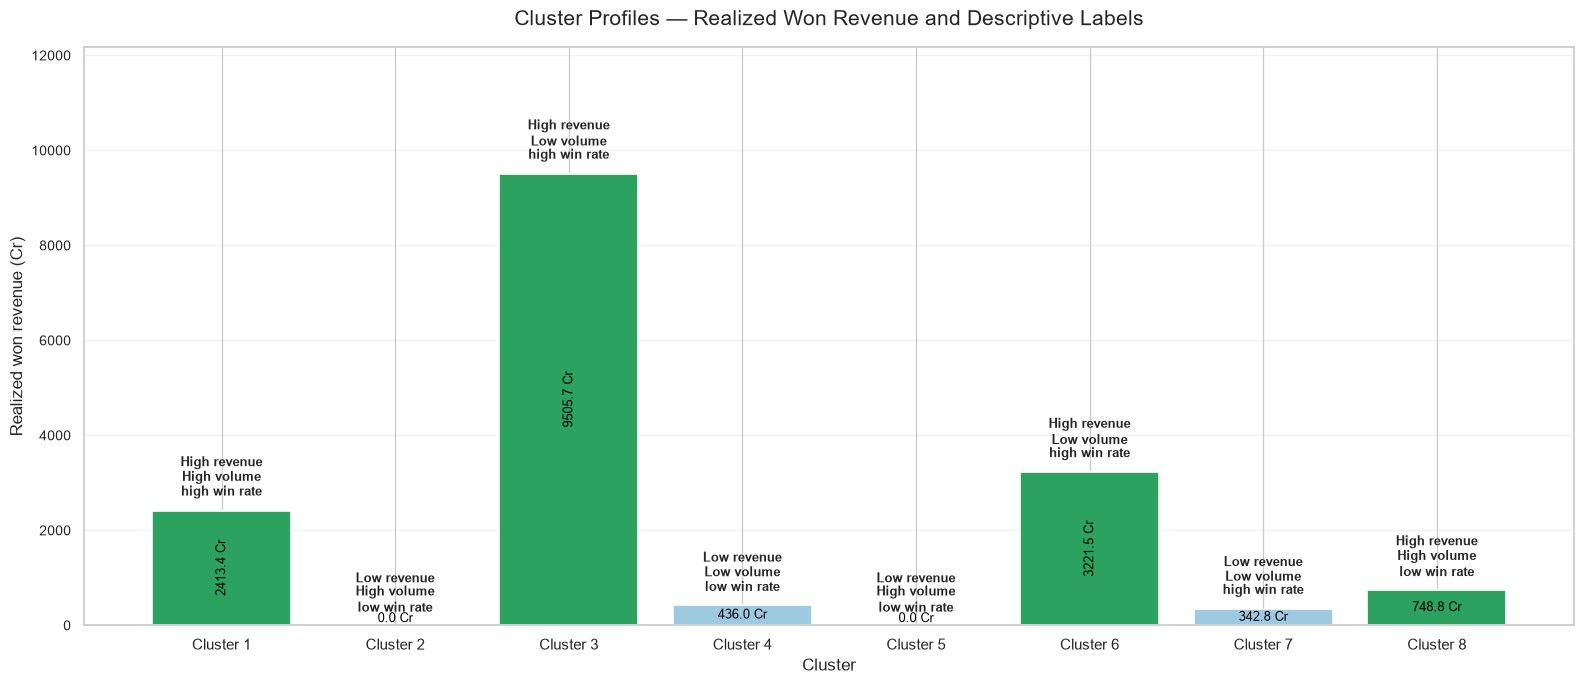

In [12]:
# Additional cluster interpretation chart (added without changing existing analysis cells)
# Cluster IDs are arbitrary; the short labels below summarize each cluster's observed profile.
cluster_profile = comb.groupby("KMeans_Cluster").agg(
    Opportunities=("Opportunities", "sum"),
    Rate_Closed=("Rate_Closed", "sum"),
    Rate_Wins=("Rate_Wins", "sum"),
    Won_Revenue_Cr=("Won_Revenue_Cr", "sum")
).reset_index()
cluster_profile["Win_Rate_Pct"] = np.where(
    cluster_profile["Rate_Closed"] > 0,
    100 * cluster_profile["Rate_Wins"] / cluster_profile["Rate_Closed"],
    np.nan
)
cluster_profile = cluster_profile.sort_values("KMeans_Cluster").copy()

# Compare each cluster with the median across clusters to produce data-driven descriptive labels.
revenue_mid = cluster_profile["Won_Revenue_Cr"].median()
volume_mid = cluster_profile["Opportunities"].median()
valid_rates = cluster_profile["Win_Rate_Pct"].dropna()
rate_mid = valid_rates.median() if not valid_rates.empty else np.nan

def describe_cluster(row):
    revenue_level = "High revenue" if row["Won_Revenue_Cr"] >= revenue_mid else "Low revenue"
    volume_level = "High volume" if row["Opportunities"] >= volume_mid else "Low volume"
    if pd.isna(row["Win_Rate_Pct"]):
        rate_level = "no closed outcomes"
    else:
        rate_level = "high win rate" if row["Win_Rate_Pct"] >= rate_mid else "low win rate"
    return f"{revenue_level}\n{volume_level}\n{rate_level}"

cluster_profile["Cluster_Label"] = cluster_profile.apply(describe_cluster, axis=1)
cluster_profile["Cluster_Display"] = cluster_profile["KMeans_Cluster"].astype(int).add(1).map(lambda n: f"Cluster {n}")

fig, ax = plt.subplots(figsize=(16, 7))
bars = ax.bar(
    cluster_profile["Cluster_Display"],
    cluster_profile["Won_Revenue_Cr"],
    color=["#2ca25f" if v >= revenue_mid else "#9ecae1" for v in cluster_profile["Won_Revenue_Cr"]],
    edgecolor="white", linewidth=1.2
)
ax.set_title("Cluster Profiles — Realized Won Revenue and Descriptive Labels", fontsize=15, pad=16)
ax.set_xlabel("Cluster", fontsize=12)
ax.set_ylabel("Realized won revenue (Cr)", fontsize=12)
ax.tick_params(axis="x", labelsize=11)
ax.tick_params(axis="y", labelsize=10)
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)

max_revenue = max(cluster_profile["Won_Revenue_Cr"].max(), 0.1)
ax.set_ylim(0, max_revenue * 1.28)
for bar, (_, row) in zip(bars, cluster_profile.iterrows()):
    label_y = bar.get_height() + max_revenue * 0.025
    ax.text(
        bar.get_x() + bar.get_width() / 2, label_y,
        row["Cluster_Label"], ha="center", va="bottom", fontsize=9,
        fontweight="bold", linespacing=1.25
    )
    ax.text(
        bar.get_x() + bar.get_width() / 2, max(bar.get_height() * 0.5, max_revenue * 0.015),
        f"{row['Won_Revenue_Cr']:.1f} Cr", ha="center", va="center", fontsize=9,
        color="black", rotation=90 if bar.get_height() > max_revenue * 0.15 else 0
    )
plt.tight_layout()
plt.show()


## 9. Export results



In [13]:
OUTPUT_DIR = Path("universal_sales_analysis_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)
raw.to_csv(OUTPUT_DIR / "cleaned_universal_dataset.csv", index=False)
monthly_revenue.rename("Actual_Won_Revenue_Cr").to_csv(OUTPUT_DIR / "monthly_historical_revenue.csv")
forecast.rename("Forecast_Won_Revenue_Cr").to_csv(OUTPUT_DIR / "next_12_month_forecast.csv")
rep.to_csv(OUTPUT_DIR / "sales_representative_performance.csv", index=False)
customer.to_csv(OUTPUT_DIR / "customer_type_segmentation.csv", index=False)
comb.to_csv(OUTPUT_DIR / "combination_clustering.csv", index=False)
comb.sort_values("Won_Revenue_Cr", ascending=False).to_csv(OUTPUT_DIR / "combinations_ranked_by_won_revenue.csv", index=False)
cluster_summary.to_csv(OUTPUT_DIR / "cluster_summary.csv", index=False)
top_revenue.to_csv(OUTPUT_DIR / "top_revenue_combinations.csv", index=False)
bottom_revenue.to_csv(OUTPUT_DIR / "bottom_revenue_combinations.csv", index=False)
improve.to_csv(OUTPUT_DIR / "improvement_candidates.csv", index=False)
print("Saved CSV outputs to:", OUTPUT_DIR.resolve())


Saved CSV outputs to: C:\Users\geete\KMB Projects\universal_sales_analysis_outputs
